## <div align="center"> IS388 Data Analysis </div>
## <div align="center"> Final Project [Data Inventory Analysis]</div>
#### <div align="center"> Semester Ganjil 2025/2026 </div>

In [1]:
import datetime
import uuid

studentName = "Nikki Tirta Iwan"
studentNIM = "00000112922"
studentClass = "IS388-EL"

In [2]:
myDate = datetime.datetime.now()
myDevice = str(uuid.uuid1())

print("Name: \t\t{}".format(studentName))
print("NIM: \t\t{}".format(studentNIM))
print("NIM: \t\t{}".format(studentClass))
print("Start: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Nikki Tirta Iwan
NIM: 		00000112922
NIM: 		IS388-EL
Start: 		2025-12-23 07:59:46.011962
Device ID: 	ac7a016d-df9a-11f0-9231-c8530905bba6


---
## <div align="center">Library Importing</div>
---

In [3]:
#Main Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats

#Train Test Split & Smoothing
from sklearn.model_selection import train_test_split

#evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric


#other
import prophet as Prophet
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
import matplotlib.dates as mdates


---
## <div align="center">Inserting Data</div>
---

In [4]:
CDA = pd.read_csv('salesFinal2016.csv',chunksize = 100000)

In [5]:
Df = []
for chunk in CDA:
    Df.append(chunk)

sales = pd.concat(Df)

In [6]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12825363 entries, 0 to 12825362
Data columns (total 14 columns):
 #   Column          Dtype  
---  ------          -----  
 0   InventoryId     object 
 1   Store           int64  
 2   Brand           int64  
 3   Description     object 
 4   Size            object 
 5   SalesQuantity   int64  
 6   SalesDollars    float64
 7   SalesPrice      float64
 8   SalesDate       object 
 9   Volume          float64
 10  Classification  int64  
 11  ExciseTax       float64
 12  VendorNo        int64  
 13  VendorName      object 
dtypes: float64(4), int64(5), object(5)
memory usage: 1.3+ GB


---
## <div align="center">Pre-Processing Data</div>
---

In [7]:
#this is just to drop classification column

sales = sales.drop("Classification",axis=1)

In [8]:
#cleaning data so it is all in lowercase and remove spacing, tabbing, etc

cleansize = sales['Size'].str.lower().str.replace('"', '').str.strip()

In [9]:
#standardizing Size into whole numeric

stdSize = cleansize.str.extract(r'(\d+\.?\d*)')[0].astype(float).fillna(0)

In [10]:
#Standardizing Size into whole numeric (for PK)

stdPack = cleansize.str.extract(r'(\d+)\s*pk')[0].astype(float).fillna(1)

In [11]:
#Basic equation to normalize size into ml
multiplier = np.where(cleansize.str.contains('ml'), 1, 
             np.where(cleansize.str.contains('l'), 1000,
             np.where(cleansize.str.contains('oz'), 30, 0)))

# Trues size counted by standardized size * multiplier * standardized pack
sales['True Size/ml'] = stdSize * multiplier * stdPack
sales

,InventoryId,Store,Brand,Description,Size,SalesQuantity,SalesDollars,SalesPrice,SalesDate,Volume,ExciseTax,VendorNo,VendorName,True Size/ml
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-01,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2016-01-02,750.0,1.57,12546,JIM BEAM BRANDS COMPANY,750.0
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-03,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0
3,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,14.49,14.49,2016-01-08,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0
4,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,2,69.98,34.99,2016-01-09,375.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12825358,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-17,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0
12825359,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-21,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0
12825360,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,3,77.97,25.99,2016-12-23,750.0,2.36,9165,ULTRA BEVERAGE COMPANY LLP,750.0
12825361,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-24,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0


In [12]:
#remove any 0 value in True Size

sales = sales[sales['True Size/ml'] > 0]

#for emergency
sales2 = sales.copy()

In [13]:
sales.rename(columns={'SalesDollars': 'TotalSales'}, inplace=True)
sales['TotalSize'] = sales['True Size/ml'] * sales['SalesQuantity']
sales['CleanProfit'] = sales['TotalSales'] - sales['ExciseTax']
sales

C:\Users\Nikki\AppData\Local\Temp\ipykernel_30056\1887423309.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sales.rename(columns={'SalesDollars': 'TotalSales'}, inplace=True)
C:\Users\Nikki\AppData\Local\Temp\ipykernel_30056\1887423309.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sales['TotalSize'] = sales['True Size/ml'] * sales['SalesQuantity']
C:\Users\Nikki\AppData\Local\Temp\ipykernel_30056\1887423309.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value i

,InventoryId,Store,Brand,Description,Size,SalesQuantity,TotalSales,SalesPrice,SalesDate,Volume,ExciseTax,VendorNo,VendorName,True Size/ml,TotalSize,CleanProfit
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-01,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.70
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2016-01-02,750.0,1.57,12546,JIM BEAM BRANDS COMPANY,750.0,1500.0,31.41
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-03,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.70
3,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,14.49,14.49,2016-01-08,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,13.70
4,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,2,69.98,34.99,2016-01-09,375.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,1500.0,69.19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12825358,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-17,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0,750.0,25.20
12825359,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-21,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0,750.0,25.20
12825360,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,3,77.97,25.99,2016-12-23,750.0,2.36,9165,ULTRA BEVERAGE COMPANY LLP,750.0,2250.0,75.61
12825361,9_BLACKPOOL_984,9,984,Patron XO Cafe Liqueur,750mL,1,25.99,25.99,2016-12-24,750.0,0.79,9165,ULTRA BEVERAGE COMPANY LLP,750.0,750.0,25.20


In [14]:
sales['is_bulk'] = sales['Size'].str.contains('Pk', case = False, na = False).astype(int)

bulk_samples = sales[sales['is_bulk'] == 1][['Size', 'is_bulk']].drop_duplicates().head(10)
print(bulk_samples)

print(sales['is_bulk'].value_counts())
sales.head()

             Size  is_bulk
4      375mL 2 Pk        1
17      50mL 4 Pk        1
31     750mL 3 Pk        1
93     375mL 3 Pk        1
99     200mL 3 Pk        1
202     50mL 3 Pk        1
340    100mL 4 Pk        1
1069    50mL 5 Pk        1
3470   187mL 4 Pk        1
10710  250mL 4 Pk        1
is_bulk
0    12512725
1       91289
Name: count, dtype: int64


C:\Users\Nikki\AppData\Local\Temp\ipykernel_30056\1027354274.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sales['is_bulk'] = sales['Size'].str.contains('Pk', case = False, na = False).astype(int)


,InventoryId,Store,Brand,Description,Size,SalesQuantity,TotalSales,SalesPrice,SalesDate,Volume,ExciseTax,VendorNo,VendorName,True Size/ml,TotalSize,CleanProfit,is_bulk
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-01,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.70,0
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2016-01-02,750.0,1.57,12546,JIM BEAM BRANDS COMPANY,750.0,1500.0,31.41,0
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-03,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.70,0
3,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,14.49,14.49,2016-01-08,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,13.70,0
4,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,2,69.98,34.99,2016-01-09,375.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,1500.0,69.19,1


In [15]:
sales['is_bulk'] = sales['Size'].str.contains('Pk', case = False, na = False).astype(int)

bulk_samples = sales[sales['is_bulk'] == 1][['Size', 'is_bulk']].drop_duplicates().head(10)
print(bulk_samples)

print(sales['is_bulk'].value_counts())
sales.head()

             Size  is_bulk
4      375mL 2 Pk        1
17      50mL 4 Pk        1
31     750mL 3 Pk        1
93     375mL 3 Pk        1
99     200mL 3 Pk        1
202     50mL 3 Pk        1
340    100mL 4 Pk        1
1069    50mL 5 Pk        1
3470   187mL 4 Pk        1
10710  250mL 4 Pk        1
is_bulk
0    12512725
1       91289
Name: count, dtype: int64


C:\Users\Nikki\AppData\Local\Temp\ipykernel_30056\1027354274.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sales['is_bulk'] = sales['Size'].str.contains('Pk', case = False, na = False).astype(int)


,InventoryId,Store,Brand,Description,Size,SalesQuantity,TotalSales,SalesPrice,SalesDate,Volume,ExciseTax,VendorNo,VendorName,True Size/ml,TotalSize,CleanProfit,is_bulk
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-01,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.70,0
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2016-01-02,750.0,1.57,12546,JIM BEAM BRANDS COMPANY,750.0,1500.0,31.41,0
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-03,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.70,0
3,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,14.49,14.49,2016-01-08,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,13.70,0
4,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,2,69.98,34.99,2016-01-09,375.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,1500.0,69.19,1


In [16]:
# Binning menggunakan equal-width
bins = [0, 100, 500, 1000, sales['TotalSales'].max()]
labels = ['Low', 'Medium', 'High', 'Very High']

sales['Sales_Category'] = pd.cut(
    sales['TotalSales'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

sales[['TotalSales', 'Sales_Category']].head(10)

C:\Users\Nikki\AppData\Local\Temp\ipykernel_30056\10670157.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sales['Sales_Category'] = pd.cut(


,TotalSales,Sales_Category
0,16.49,Low
1,32.98,Low
2,16.49,Low
3,14.49,Low
4,69.98,Low
5,34.99,Low
6,34.99,Low
7,34.99,Low
8,59.96,Low
9,14.99,Low


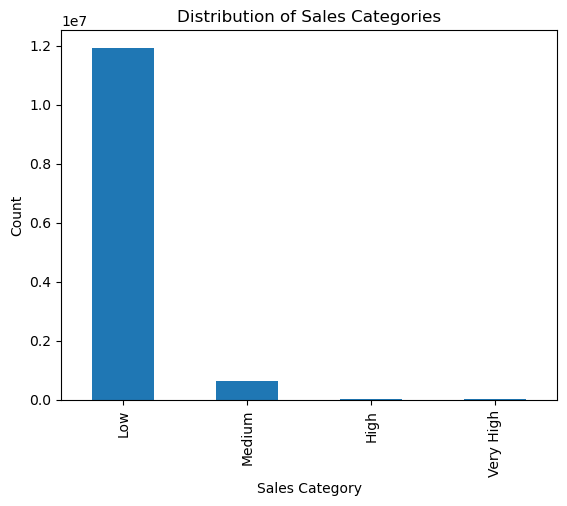

In [17]:
import matplotlib.pyplot as plt

sales['Sales_Category'].value_counts().plot(kind='bar')
plt.title('Distribution of Sales Categories')
plt.xlabel('Sales Category')
plt.ylabel('Count')
plt.show()

---
## <div align="center">Exploratory Data Analysis (EDA)</div>
---

<div align="center">Time Series Plot</div>

For our first visualizations is seeing the SalesDate with cleanProfit. This visualization helps in raising questions such as “How often does the profit goes up”, and “At what day or month did our store profit goes up”. From this plot we can see what might be the reason the store profit goes up

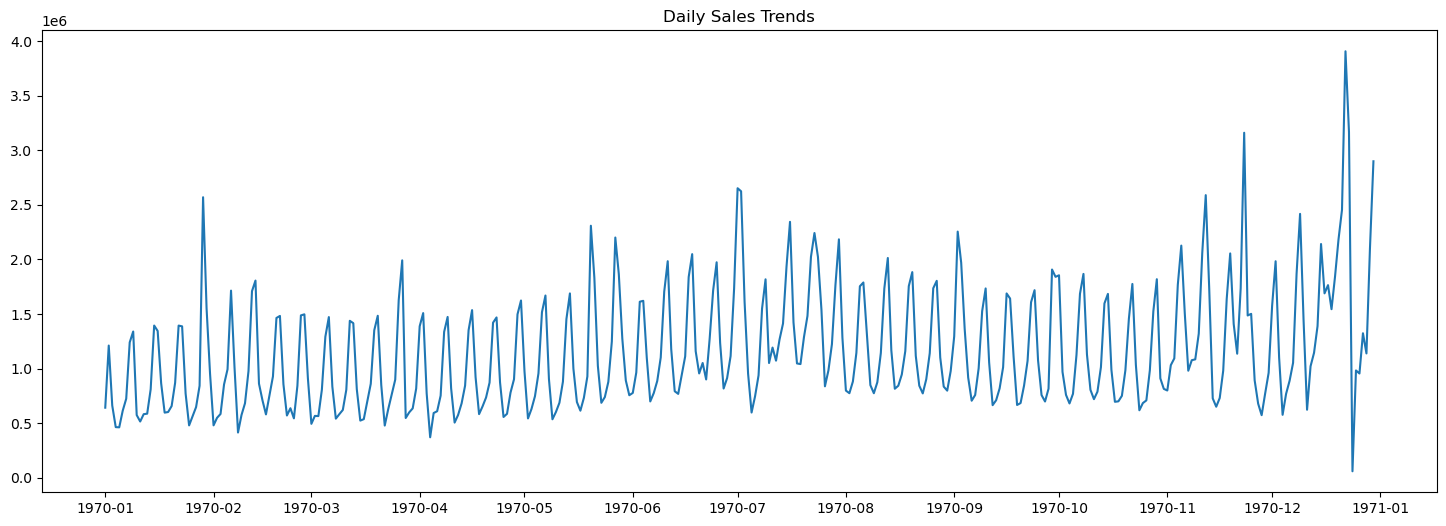

In [18]:
#seeing the trend of daily sales with TotalSales as y axis 
#TotalSales is the total customer bought in a single alcohol transaction, it is multiplied from salesquantity and salesprice 

plt.figure(figsize=(18,6))
sales_daily = sales.groupby('SalesDate')['CleanProfit'].sum().reset_index()
plt.plot(sales_daily['SalesDate'], sales_daily['CleanProfit'])
#getting the current axis
ax = plt.gca()
#setting tick so that it shows only the first day of each month
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
#setting the date format on x axis
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.title('Daily Sales Trends')
plt.show()

<div align="center">Bar plot</div>

For the second visualizations is the top 10 brands by its clean profit. This insight is good because we can see which brand perform the best and in here we can see jack daniels is the best selling alcohol, this can be made into decision such as increasing the inventory on jack daniels, or doing partnership with jack daniels

C:\Users\Nikki\AppData\Local\Temp\ipykernel_30056\1798635916.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=topbrands.values, y=topbrands.index, palette='viridis')


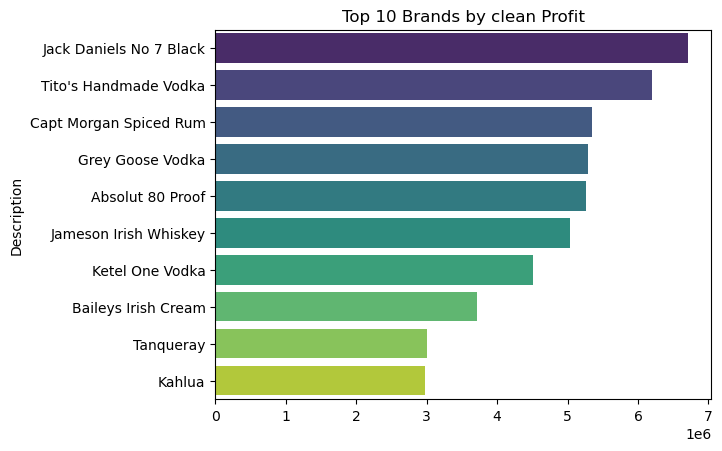

In [19]:
#showing the top most sold brands by its sales by dollars

topbrands = sales.groupby('Description')['CleanProfit'].sum().nlargest(10)
sns.barplot(x=topbrands.values, y=topbrands.index, palette='viridis')
plt.title('Top 10 Brands by clean Profit')
plt.show()

<div align="center">Heatmap</div>

Heatmap is used to see the correlation between variable, this is important for predictive modelling as a statistical sanity check.

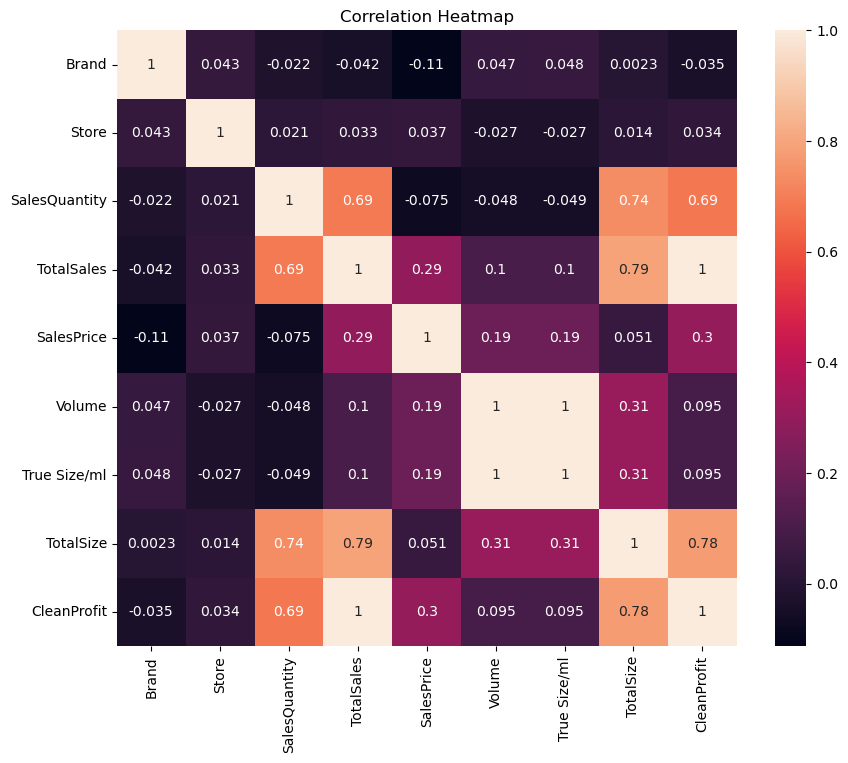

In [20]:
#heatmap correlation is to see how strong the relationship between variables are

plt.figure(figsize=(10,8))
sns.heatmap(sales[['Brand', 'Store', 'SalesQuantity', 'TotalSales', 'SalesPrice', 'Volume', 'True Size/ml', 'TotalSize', 'CleanProfit']].corr(), annot=True)
plt.title('Correlation Heatmap')
plt.show()

<div align="center">Pie chart</div>

The pie chart shows that 750 ml is the most buy product size. The reason for using pie chart is because it clearly segmented each part, which is satisfying for investor to see.

In [21]:
#grouping the sales for pie chart by size and TotalSales
size_sales = sales.groupby('Size')['TotalSales'].sum().sort_values(ascending=False)
top5 = size_sales.head(5)
#others is basically all the rest of the sizes after top 5, they summed up. iloc is to get all the rows after index 5
others = pd.Series({'Others': size_sales.iloc[5:].sum()})
pie = pd.concat([top5, others])

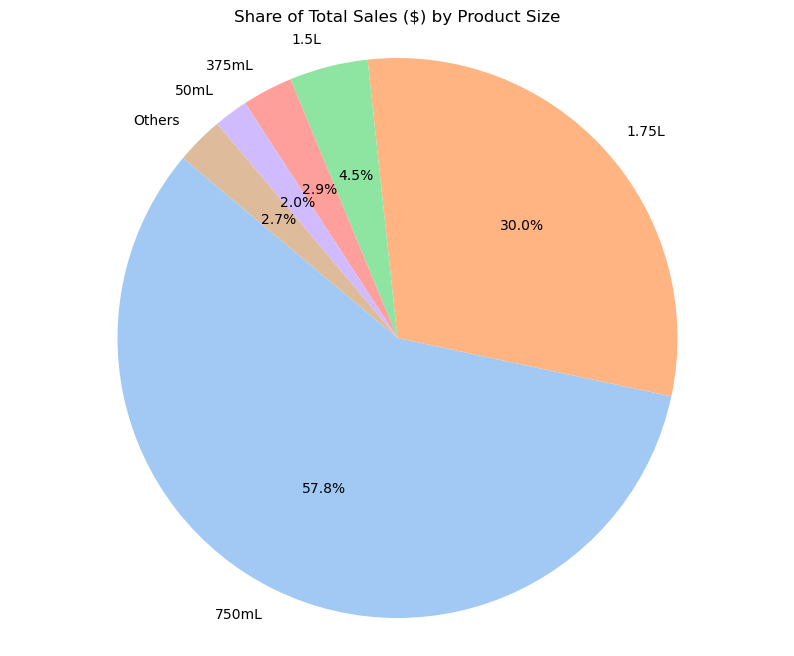

In [22]:
#this is the pie chart, autopct is to automatically make percentage, f means it is decimal number, .1 means the precision
plt.figure(figsize=(10, 8))
plt.pie(pie, labels=pie.index, autopct='%1.1f%%', startangle=140, 
        colors=sns.color_palette('pastel'))
plt.title('Share of Total Sales ($) by Product Size')
plt.axis('equal')
plt.show()

In [23]:
sales.head(1)

,InventoryId,Store,Brand,Description,Size,SalesQuantity,TotalSales,SalesPrice,SalesDate,Volume,ExciseTax,VendorNo,VendorName,True Size/ml,TotalSize,CleanProfit,is_bulk,Sales_Category
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2016-01-01,750.0,0.79,12546,JIM BEAM BRANDS COMPANY,750.0,750.0,15.7,0,Low


In [24]:
TimeSales = sales[["SalesDate","CleanProfit"]]

In [25]:
monthsales = TimeSales.groupby('SalesDate')['CleanProfit'].sum().reset_index()
print(monthsales.head())

    SalesDate  CleanProfit
0  2016-01-01    641722.45
1  2016-01-02   1210710.96
2  2016-01-03    661274.94
3  2016-01-04    463738.66
4  2016-01-05    461901.00


In [26]:
monthsales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364 entries, 0 to 363
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SalesDate    364 non-null    object 
 1   CleanProfit  364 non-null    float64
dtypes: float64(1), object(1)
memory usage: 5.8+ KB


In [27]:
# 1. Reset the index to ensure it's clean and unique
monthsales = monthsales.reset_index(drop=True)

# 2. Force conversion to datetime again (just to be absolutely safe)
monthsales['SalesDate'] = pd.to_datetime(monthsales['SalesDate'])

monthsales['Month'] = monthsales['SalesDate'].dt.to_period('M')

monthsales = monthsales.groupby('Month')['CleanProfit'].sum().reset_index()
monthsales['SalesDate_Plot'] = monthsales['Month'].dt.to_timestamp()

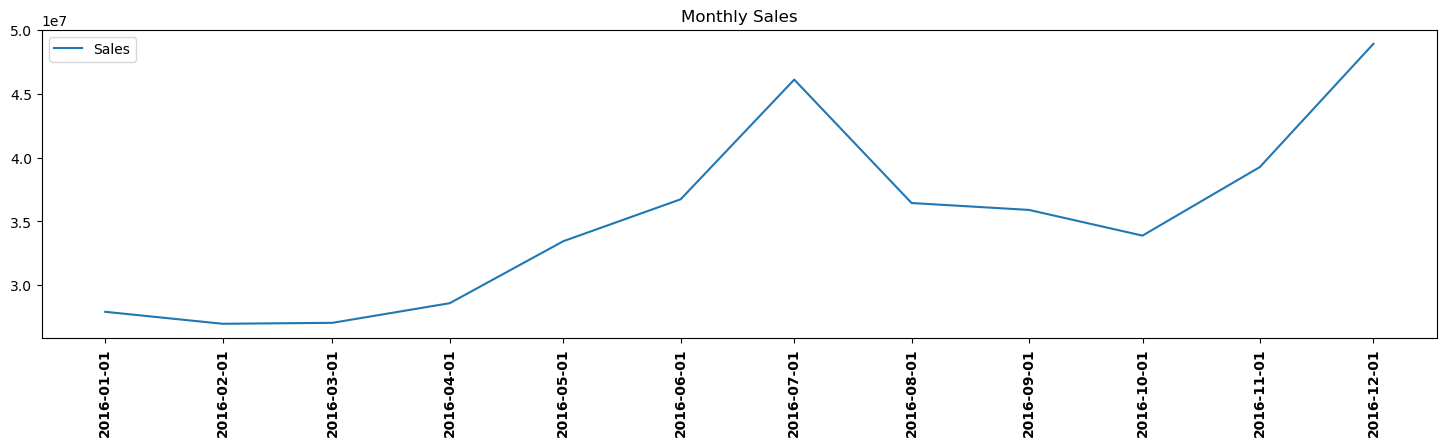

In [28]:
plt.figure(figsize=(18,4))

plt.plot(monthsales['SalesDate_Plot'], monthsales['CleanProfit'], label='Sales')

plt.legend(loc='best')
plt.title('Monthly Sales')
plt.xticks(monthsales['SalesDate_Plot'],rotation=90, fontweight="bold")
plt.show()

<div align="center">Scatter Plot</div>

Scatter plot reveals that higher prices lead to higher profit per bottle. Second, the data shows that customers mostly buy cheaper bottles ($10 - $30). This proves the business relies on selling a high volume low cost items to stay profitable, rather than depending on expensive, high margin products.

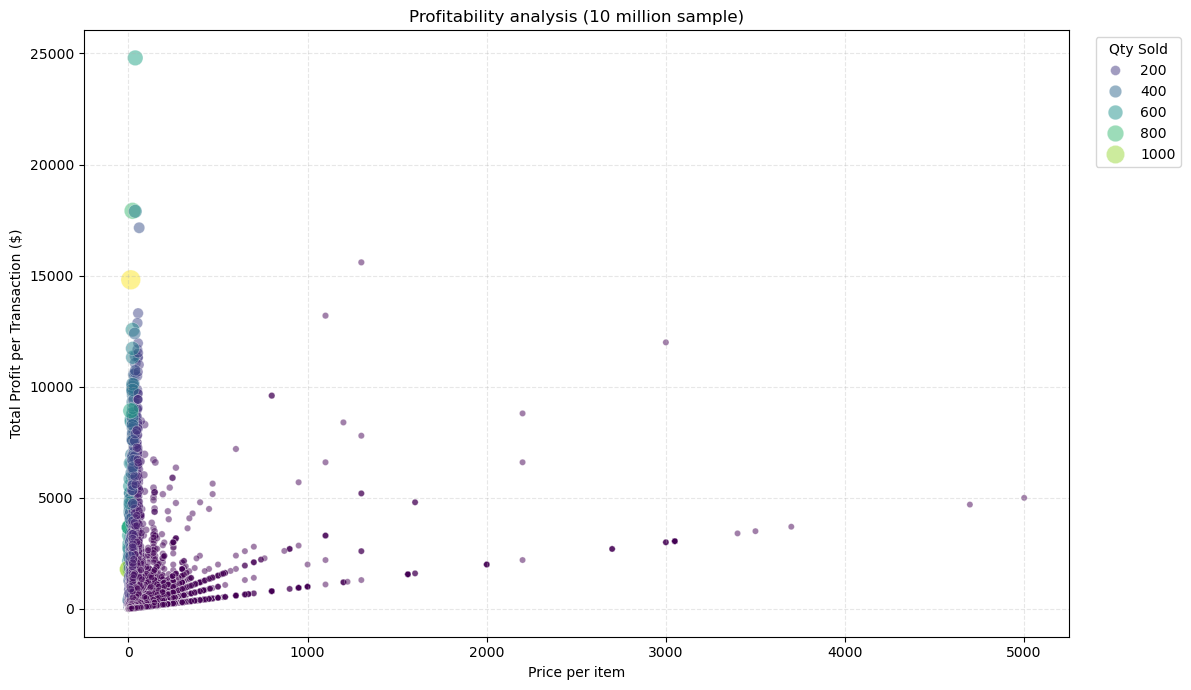

In [29]:
# Ambil sampel 10.000 baris agar ringan saat loading
sales_sample = sales.sample(10000000, random_state=42)

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=sales_sample, # Gunakan data sampel di sini
    x='SalesPrice', 
    y='CleanProfit', 
    hue='SalesQuantity', 
    size='SalesQuantity',
    sizes=(20, 200),      
    palette='viridis',   
    alpha=0.5 # Alpha rendah membantu melihat tumpukan data
)

plt.title('Profitability analysis (10 million sample)')
plt.xlabel('Price per item')
plt.ylabel('Total Profit per Transaction ($)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='Qty Sold', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

---
## <div align="center">Prophet Model</div>
---

In [30]:

salesClean = sales.copy()

z_scores = np.abs(stats.zscore(salesClean['CleanProfit']))
threshold = 3
salesClean = salesClean[(z_scores < threshold)]

08:14:13 - cmdstanpy - INFO - Chain [1] start processing
08:14:13 - cmdstanpy - INFO - Chain [1] done processing


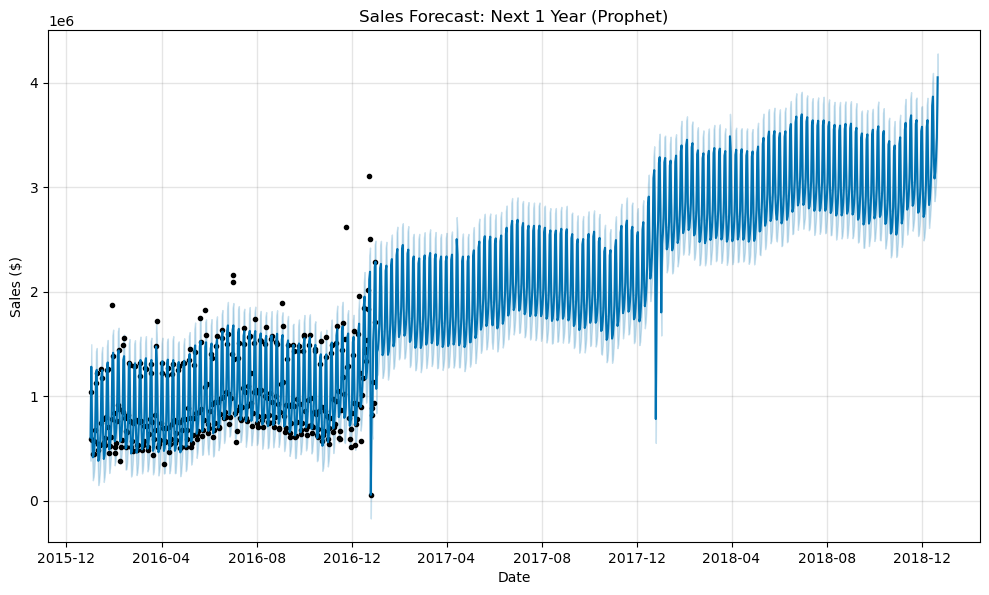

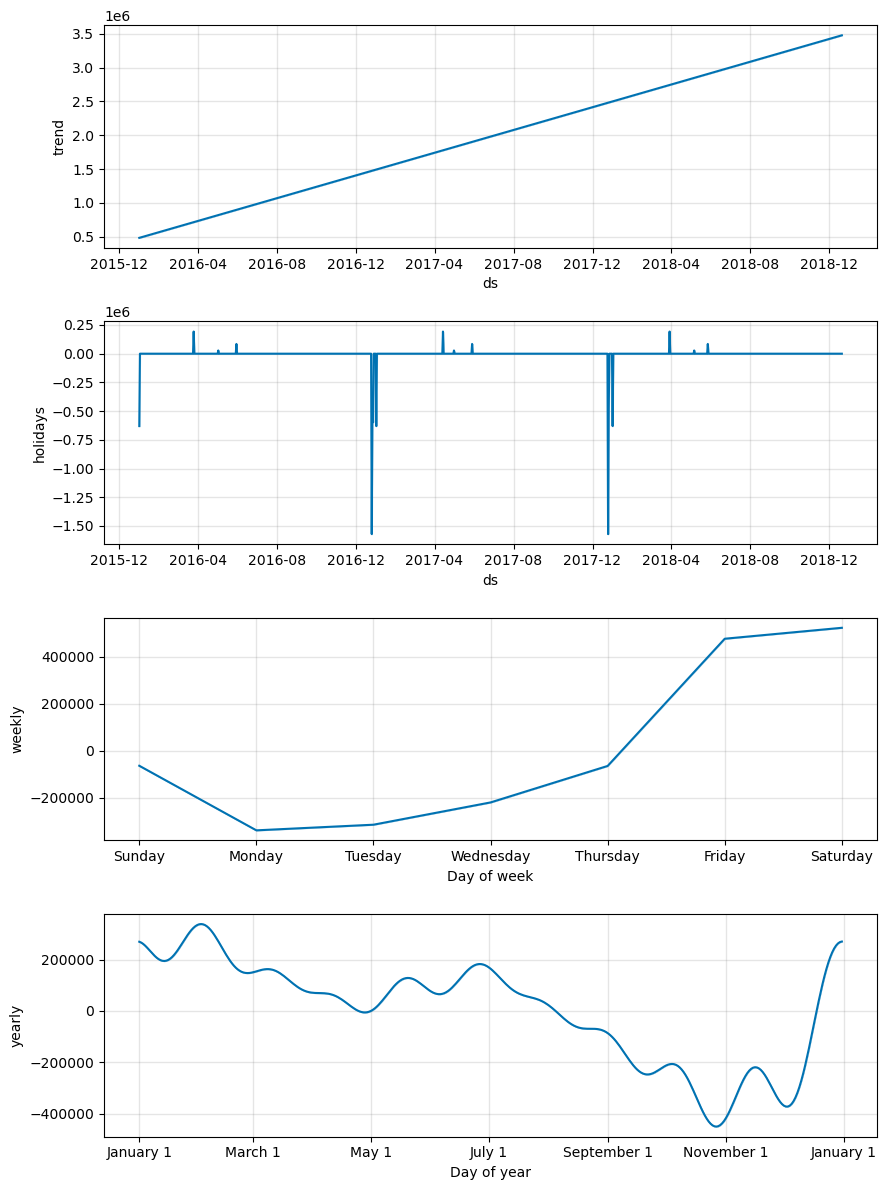

In [31]:
#prophet model is a time series model from facebook that works great when there is a strong seasonal pattern 




# Prophet requires two specific column names: 'ds' (Date) and 'y' (Value)
salesClean['SalesDate'] = pd.to_datetime(salesClean['SalesDate'])
sales_prophet_zsc = salesClean.groupby('SalesDate')['CleanProfit'].sum().reset_index()
#ds stands for Date Stamp and its already hard coded so it cant be changed and y is the target variable also cant be changed. 
#basically ds looks for the specific label of times
sales_prophet_zsc.columns = ['ds', 'y']

#configure prophet model
#here we can do configuration of which seasonality is present. its not daily so note it as False, it is weekly because on saturday and sunday the sales goes up, and it is yearly because on special holidays the sales go up
model_zsc = Prophet.Prophet(daily_seasonality=False,  weekly_seasonality=True, yearly_seasonality=True)
#Advantage of prophet is it already predefined the holidays, in this example we use UK (United Kingdom) because the data istated the location in england
model_zsc.add_country_holidays(country_name='UK')

# do some fitting
model_zsc.fit(sales_prophet_zsc)

# Making the dataframe to forecast for the future, Periods 365 means that it forecast 1 year into the future
future = model_zsc.make_future_dataframe(periods=720)

# this is where the model get predicted. state the model that have been made, future is the dataframe we already made
forecast = model_zsc.predict(future)

#making the forecasting plot 
fig1 = model_zsc.plot(forecast)
plt.title("Sales Forecast: Next 1 Year (Prophet)")
plt.xlabel("Date")
plt.ylabel("Sales ($)")
plt.show()

#the components that see the pattern from the trend pattern, the holidays impact, weekly chart that see if there is drop, and yearly that simplify the pattern for a whole year
fig2 = model_zsc.plot_components(forecast)
plt.show()

In [32]:


#this is to do testing wether or not the model is accurate. how it works is it forces the model to take history exam
#the initial is how many days the model will take to study (model will take from january 1 to january 14), horizon is the test (after it learn the 14 days, it will predict the 3 days), and period is where the next test will be help(in this case the next one is january 19th)
proph_cv_zsc = cross_validation(model_zsc, initial='14 days',  horizon='3 days', period='5 days')

#this make the evaluation test model (MAE, RMSE, MAPE) for each horizon
proph_p_zsc = performance_metrics(proph_cv_zsc)
print(proph_p_zsc.head())

Seasonality has period of 365.25 days which is larger than initial window. Consider increasing initial.


  0%|          | 0/70 [00:00<?, ?it/s]

08:14:14 - cmdstanpy - INFO - Chain [1] start processing
08:14:14 - cmdstanpy - INFO - Chain [1] done processing
08:14:14 - cmdstanpy - INFO - Chain [1] start processing
08:14:14 - cmdstanpy - INFO - Chain [1] done processing
08:14:14 - cmdstanpy - INFO - Chain [1] start processing
08:14:15 - cmdstanpy - INFO - Chain [1] done processing
08:14:15 - cmdstanpy - INFO - Chain [1] start processing
08:14:15 - cmdstanpy - INFO - Chain [1] done processing
08:14:15 - cmdstanpy - INFO - Chain [1] start processing
08:14:15 - cmdstanpy - INFO - Chain [1] done processing
08:14:15 - cmdstanpy - INFO - Chain [1] start processing
08:14:15 - cmdstanpy - INFO - Chain [1] done processing
08:14:16 - cmdstanpy - INFO - Chain [1] start processing
08:14:16 - cmdstanpy - INFO - Chain [1] done processing
08:14:16 - cmdstanpy - INFO - Chain [1] start processing
08:14:16 - cmdstanpy - INFO - Chain [1] done processing
08:14:16 - cmdstanpy - INFO - Chain [1] start processing
08:14:17 - cmdstanpy - INFO - Chain [1]

  horizon           mse           rmse            mae      mape     mdape  \
0  1 days  4.432471e+10  210534.337035  131023.545078  0.148090  0.105779   
1  2 days  1.461291e+11  382268.375316  197704.402171  0.809434  0.113927   
2  3 days  1.253815e+11  354092.561380  249020.115018  0.280302  0.218281   

      smape  coverage  
0  0.138973  0.637681  
1  0.206508  0.542857  
2  0.273600  0.357143  


In [33]:
#this calculates the r square score. the first line will turn the date column to index so the prediction table lines up with the actual data table
#next, join is to merge two table between y and yhat, y is the actual sales that happened and yhat is the model prediction
#dropna() will remove the 365 days of future prediction and only take the testing
metric_df_zsc = forecast.set_index('ds')[['yhat']].join(sales_prophet_zsc.set_index('ds').y).dropna()

# this will calculate the r2 score. using the y and yhat is to compare the actual against the predictions
r2 = r2_score(metric_df_zsc.y, metric_df_zsc.yhat)
mae = mean_absolute_error(metric_df_zsc.y, metric_df_zsc.yhat)
mse = mean_squared_error(metric_df_zsc.y, metric_df_zsc.yhat)

print(f"r2 score prophet: {r2}")
print(f"mae score prophet: {mae}")
print(f"mse score prophet: {mse}")

#this model might noly be good to see how the seasonality, trend, etc fits the testing

r2 score prophet: 0.8348906468542606
mae score prophet: 90515.99243584705
mse score prophet: 29565117580.086018


---
## <div align="center">Stationarity Checking</div>
---

In [34]:

# 1. Aggregate the data by Date first!
# Assuming 'SalesDate' is your date column and it is already in datetime format
daily_sales_series = salesClean.groupby('SalesDate')['CleanProfit'].sum()


def check_stationarity(timeseries, title="Time Series"):
    print(f"Results of Dickey-Fuller Test for: {title}")
    
    # Drop NaNs to prevent errors
    timeseries = timeseries.dropna()

    # Perform the test
    # autolag='AIC' is fast on aggregated data, slow on raw data
    saletest = adfuller(timeseries, autolag='AIC')
    
    salesoutput = pd.Series(saletest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])

    for key, value in saletest[4].items():
        salesoutput[f'Critical Value ({key})'] = value

    # Print results OUTSIDE the loop
    print(salesoutput)
    
    print("\nInterpretation:")
    if salesoutput['p-value'] <= 0.05:
        print("✅ p-value <= 0.05: The series is STATIONARY.")
    else:
        print("❌ p-value > 0.05: The series is NON-STATIONARY.")
    print("-" * 50)
# 2. Run the stationarity check on the AGGREGATED series
check_stationarity(daily_sales_series, title="Daily Sales Dollars")

Results of Dickey-Fuller Test for: Daily Sales Dollars
Test Statistic                  -1.649923
p-value                          0.457081
#Lags Used                      14.000000
Number of Observations Used    349.000000
Critical Value (1%)             -3.449227
Critical Value (5%)             -2.869857
Critical Value (10%)            -2.571201
dtype: float64

Interpretation:
❌ p-value > 0.05: The series is NON-STATIONARY.
--------------------------------------------------


In [35]:
# --- LANGKAH 1: Lakukan Differensiasi (Agar Stationer) ---
# Mengurangkan data hari ini dengan data hari sebelumnya
sales_diff = daily_sales_series.diff().dropna()
# Cek Stationaritas pada data hasil differensiasi
print("\n" + "="*50)
print("HASIL SETELAH DIFFERENSIASI (ORDER 1)")
print("="*50)
check_stationarity(sales_diff, title="Sales (Differenced)")



HASIL SETELAH DIFFERENSIASI (ORDER 1)
Results of Dickey-Fuller Test for: Sales (Differenced)
Test Statistic                -7.828078e+00
p-value                        6.401516e-12
#Lags Used                     1.300000e+01
Number of Observations Used    3.490000e+02
Critical Value (1%)           -3.449227e+00
Critical Value (5%)           -2.869857e+00
Critical Value (10%)          -2.571201e+00
dtype: float64

Interpretation:
✅ p-value <= 0.05: The series is STATIONARY.
--------------------------------------------------


---
## <div align="center">SARIMAX</div>
---

In [36]:
#training 
train_diff = sales_diff.loc[:'2016-08-29']
test_diff = sales_diff.loc['2016-08-30':]
print(f"Training on {len(train_diff)} differenced observations.")

Training on 240 differenced observations.


In [37]:

# --- 4. SARIMAX on Sales_Diff ---
# Note: order=(1, 0, 1). We set d=0 because input is ALREADY differenced.
model = SARIMAX(train_diff, 
                order=(1, 0, 1), 
                seasonal_order=(0, 1, 1, 7), 
                enforce_stationarity=True, 
                enforce_invertibility=True)

results = model.fit(disp=False)

# Forecast (Predicts changes)
forecast_obj = results.get_forecast(steps=len(test_diff))
pred_diff = forecast_obj.predicted_mean
conf_int = forecast_obj.conf_int()

c:\Users\Nikki\anaconda3\envs\00000112922_NikkiTirtaIwan\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Nikki\anaconda3\envs\00000112922_NikkiTirtaIwan\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Nikki\anaconda3\envs\00000112922_NikkiTirtaIwan\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\Nikki\anaconda3\envs\00000112922_NikkiTirtaIwan\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available.

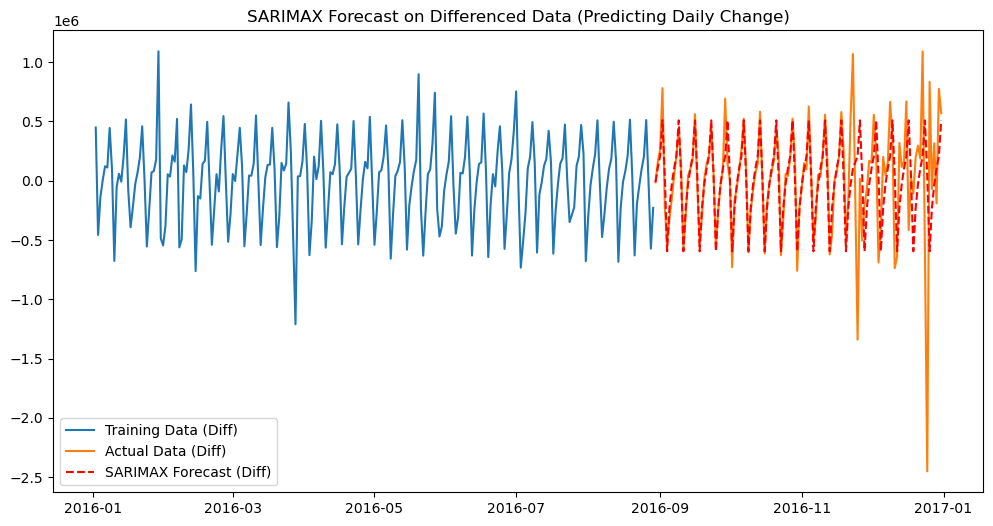

In [38]:
# --- 5. Visualization ---
plt.figure(figsize=(12, 6))

# Plot the differenced data (what the model actually sees)
plt.plot(train_diff.index, train_diff, label='Training Data (Diff)')
plt.plot(test_diff.index, test_diff, label='Actual Data (Diff)')
plt.plot(test_diff.index, pred_diff, label='SARIMAX Forecast (Diff)', color='red', linestyle='--')
plt.title('SARIMAX Forecast on Differenced Data (Predicting Daily Change)')
plt.legend()
plt.show()

In [39]:
mse_diff = mean_squared_error(test_diff, pred_diff)
mae_diff = mean_absolute_error(test_diff, pred_diff)
r2_diff = r2_score(test_diff, pred_diff)

print(f"MSE:  {mse_diff:,.2f}")
print(f"MAE:  {mae_diff:,.2f}")
print(f"R2:   {r2_diff:.4f}")

MSE:  161,675,334,801.45
MAE:  204,695.00
R2:   0.2521


In [40]:
salesSari = salesClean.groupby('SalesDate')['CleanProfit'].sum()
salesSari = salesSari.asfreq('D').fillna(0)


In [41]:
#Order is for the parameters of SARIMAX model, which is P, D, Q. p means the value of sales today is influence by the value of yesterday and if inputted 2 that means the today sales are influenced by the value of sales yesterday and the day before
# D means differencing term, to make the series stable, subtract yesterday value from today value, this help remove the underlying trend making patterns easier to mode
# q means the value of sales today is influence by the error made in forecast for yesterday, this help the model correct itself if it was consistently over or under-predicting

#the seasonal order is P, D, Q, m. its the same but its for the seasonal pattern. P means the sales today is influenced by the value from previous season
# D means subtracting the value from 7 days ago from today value
# q means the value of sales today is influence by the forecast error made 7 days ago
# m is the length of seasonal cycle

#enfore stationarity True means making the model stable by removing trends and seasonality
#enfore stationarity false means  making the model not stable and it will try to fit

#enforce invertibility ensure the model is well behaved and past observation have a decaying influence over time

Sari_train_days = salesSari.loc[:'2016-08-29']
Sari_test_days = salesSari.loc['2016-08-30':]
model_sari = SARIMAX(Sari_train_days, order=(1, 0, 1), seasonal_order=(0, 1, 1, 7), enforce_stationarity=True, enforce_invertibility=True)
results_sari = model_sari.fit()
forecast_sari = results_sari.get_forecast(steps=len(Sari_test_days))
pred_sari = forecast_sari.predicted_mean



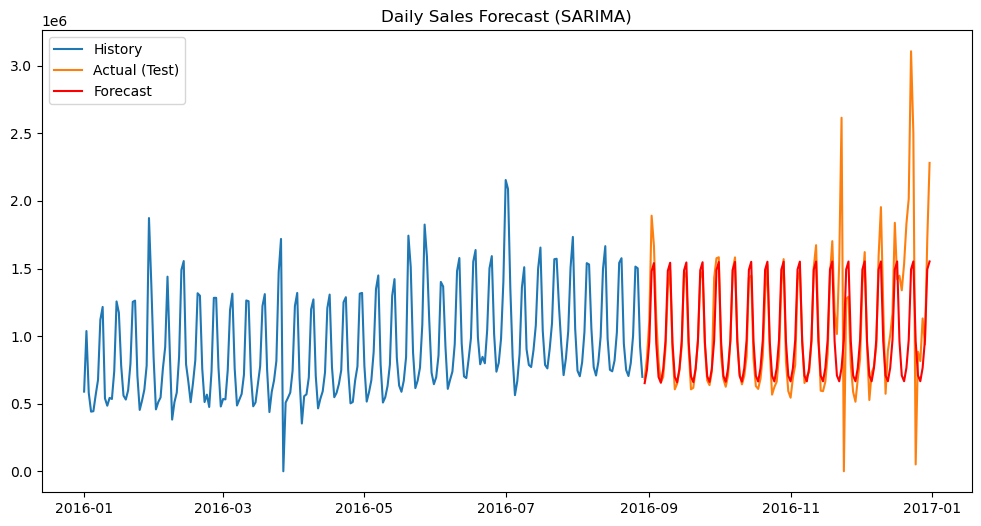

In [42]:
plt.figure(figsize=(12, 6))
plt.plot(Sari_train_days.index, Sari_train_days, label='History')
plt.plot(Sari_test_days.index, Sari_test_days, label='Actual (Test)')
plt.plot(pred_sari.index, pred_sari, label='Forecast', color='red')
plt.title('Daily Sales Forecast (SARIMA)')
plt.legend()
plt.show()

In [43]:
# Align and drop NaN values from both actual and predicted series
actual = Sari_test_days
predicted = pred_sari

# Combine into a DataFrame for safe alignment
df_r2 = pd.DataFrame({'actual': actual, 'predicted': predicted})
df_r2 = df_r2.dropna()

r2Sari = r2_score(df_r2['actual'], df_r2['predicted'])
maesari = mean_absolute_error(df_r2['actual'], df_r2['predicted'])
msesari = mean_squared_error(df_r2['actual'], df_r2['predicted'])

print(f"SARIMAX r2 score: {r2Sari}")
print(f"SARIMAX mae score: {maesari}")
print(f"SARIMAX mse score: {msesari}")

SARIMAX r2 score: 0.4845643957500466
SARIMAX mae score: 189881.7136481581
SARIMAX mse score: 127034510822.73874


In [44]:
start_date_Sarimax = '2016-3-30'
end_date_Sarimax = '2017-10-30'

pred_2017 = results_sari.predict(start=start_date_Sarimax, end=end_date_Sarimax)

print(pred_2017)

2016-03-30    5.350214e+05
2016-03-31    7.225437e+05
2016-04-01    1.260153e+06
2016-04-02    1.321924e+06
2016-04-03    6.011305e+05
                  ...     
2017-10-26    9.732347e+05
2017-10-27    1.493785e+06
2017-10-28    1.552489e+06
2017-10-29    9.614200e+05
2017-10-30    7.089098e+05
Freq: D, Name: predicted_mean, Length: 580, dtype: float64


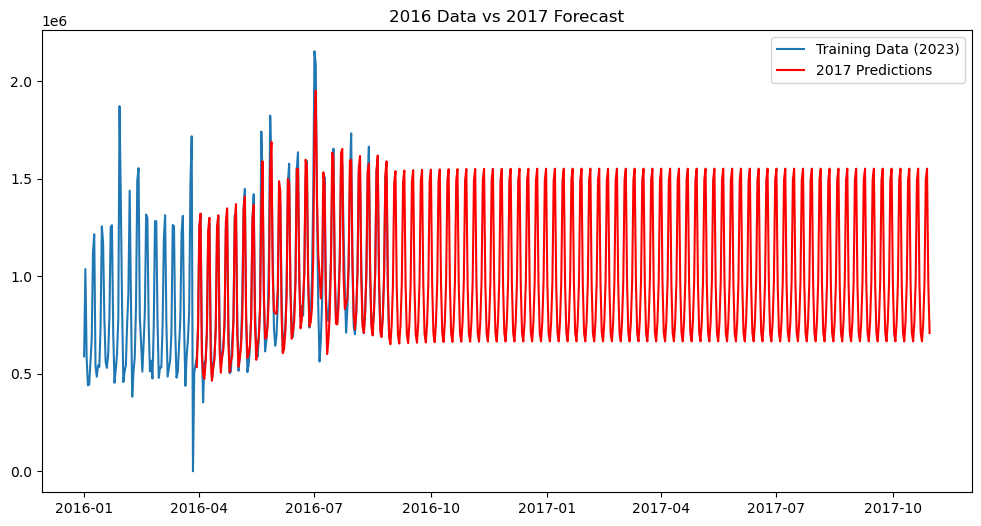

In [45]:
plt.figure(figsize=(12, 6))
# Plot the training data (jan to oct)
plt.plot(Sari_train_days.index, Sari_train_days, label='Training Data (2023)')
# plotting predictions
plt.plot(pred_2017.index, pred_2017, label='2017 Predictions', color='red')
plt.legend()
plt.title('2016 Data vs 2017 Forecast')
plt.show()

Future Improvement

SARIMAX model have a really low R2 score indicating there needs to be more parameter used for this, for example holidays parameter